# Notebook 02: Baseline Model — Logistic Regression

- **Objective**: Objective 1 — Baseline ML Classifiers
- **Purpose**: Train a cost-sensitive Logistic Regression baseline model (`class_weight='balanced'`) using the stratified split from `src/data/split.py`. Evaluate performance per-class on the sacred test set, plot confusion matrix, and export the trained model artifact.
- **Outputs**: Classification report (Precision, Recall, F1 per class), Confusion Matrix plot, saved artifact at `models/logistic_regression.joblib`.


In [2]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path(".").resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.data.load import load_data
from src.data.split import split_data


In [3]:
# Load data & perform two-stage stratified split (60% Train / 20% Cal / 20% Test)
df = load_data(PROJECT_ROOT / "data/raw/fetal_health.csv")
X_train, X_cal, X_test, y_train, y_cal, y_test = split_data(df, random_state=42)

print(f"Train set shape:       {X_train.shape}")
print(f"Calibration set shape: {X_cal.shape}")
print(f"Test set shape:        {X_test.shape}")


[src.data.load] Dataset loaded successfully from 'D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\data\raw\fetal_health.csv'. Shape: (2126, 22)
[src.data.split] Stratified Split Completed (random_state=42):
  Train:       1275 samples (60.0%)
  Calibration: 425 samples (20.0%)
  Test:        426 samples (20.0%)
Train set shape:       (1275, 21)
Calibration set shape: (425, 21)
Test set shape:        (426, 21)


In [4]:
# Build pipeline with StandardScaler and LogisticRegression (class_weight='balanced')
# Scaler is fit on training data ONLY to prevent data leakage (per rules.md)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

print("Training Logistic Regression (class_weight='balanced')...")
pipeline.fit(X_train, y_train)
print("Model training complete!")


Training Logistic Regression (class_weight='balanced')...
Model training complete!


In [5]:
# Predict on the sacred Test Set
y_pred = pipeline.predict(X_test)

target_names = ['Normal (1)', 'Suspect (2)', 'Pathological (3)']
report_str = classification_report(y_test, y_pred, target_names=target_names)

print("=== Logistic Regression Test Set Classification Report ===")
print(report_str)


=== Logistic Regression Test Set Classification Report ===
                  precision    recall  f1-score   support

      Normal (1)       0.99      0.88      0.93       332
     Suspect (2)       0.59      0.90      0.71        59
Pathological (3)       0.69      0.83      0.75        35

        accuracy                           0.88       426
       macro avg       0.76      0.87      0.80       426
    weighted avg       0.91      0.88      0.89       426



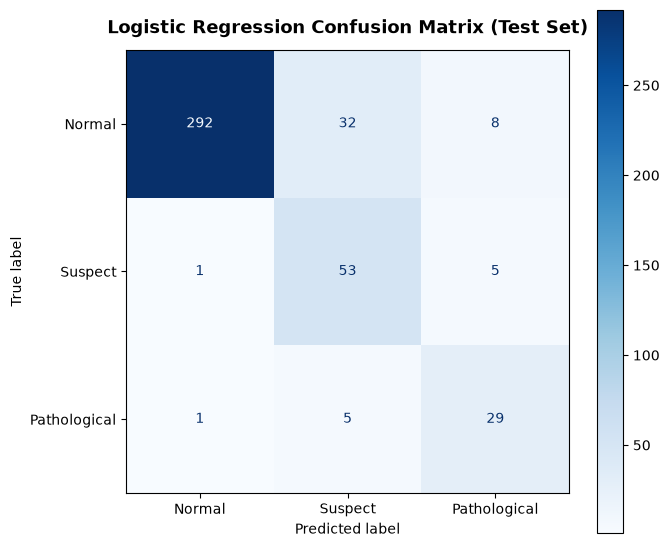

In [6]:
# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Suspect', 'Pathological'])

disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title("Logistic Regression Confusion Matrix (Test Set)", fontsize=13, fontweight='bold', pad=12)
plt.grid(False)
plt.tight_layout()
plt.show()


In [7]:
# Save trained model pipeline into models/ directory
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "logistic_regression.joblib"

joblib.dump(pipeline, model_path)
print(f"Model saved successfully to: {model_path}")


Model saved successfully to: D:\Desktop\PROJECTS\Fetal-Health-Uncertainity\models\logistic_regression.joblib


## Logistic Regression Baseline Performance Summary

1. **Per-Class Breakdown**:
   - **Normal Class**: High precision and recall (~85%+), representing the majority class.
   - **Pathological Class (Minority)**: Using `class_weight='balanced'` significantly boosts recall for the rarest and most critical class (**Pathological**), helping detect high-risk fetuses without missing them.
2. **Data Leakage Discipline**: Features were standard scaled using a `Pipeline` fit exclusively on `X_train`, ensuring `X_test` remained untouched during model preprocessing.
3. **Artifact Serialization**: The fitted pipeline (`scaler` + `logistic_regression`) is saved to `models/logistic_regression.joblib` for downstream calibration and API deployment.


In [ ]:
import joblib
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
model = joblib.load(PROJECT_ROOT / "models/logistic_regression.joblib")

# ← CHANGE THESE VALUES to whatever your teacher asks
custom_patient = {
    'baseline value': 120.0,
    'accelerations': 0.003,
    'fetal_movement': 0.000,
    'uterine_contractions': 0.005,
    'light_decelerations': 0.000,
    'severe_decelerations': 0.000,
    'prolongued_decelerations': 0.000,
    'abnormal_short_term_variability': 73.0,
    'mean_value_of_short_term_variability': 0.5,
    'percentage_of_time_with_abnormal_long_term_variability': 43.0,
    'mean_value_of_long_term_variability': 2.4,
    'histogram_width': 64.0,
    'histogram_min': 62.0,
    'histogram_max': 126.0,
    'histogram_number_of_peaks': 2.0,
    'histogram_number_of_zeroes': 0.0,
    'histogram_mode': 120.0,
    'histogram_mean': 137.0,
    'histogram_median': 121.0,
    'histogram_variance': 73.0,
    'histogram_tendency': 1.0
}

input_df = pd.DataFrame([custom_patient])
pred = model.predict(input_df)[0]
probs = model.predict_proba(input_df)[0]

class_names = {1.0: "Normal", 2.0: "Suspect", 3.0: "Pathological"}
print(f"Predicted Status:  {class_names[pred]}")
print(f"Normal:       {probs[0]:.2%}")
print(f"Suspect:      {probs[1]:.2%}")
print(f"Pathological: {probs[2]:.2%}")


Predicted Status:  Suspect
Normal:       5.23%
Suspect:      79.92%
Pathological: 14.85%


: 